# 08 - Naive Bayes trên SMS Spam Collection

Mục tiêu: dùng `CountVectorizer` và `MultinomialNB` để phân loại tin nhãn ham/spam.

## 1. Load data và EDA ngắn

Shape ban đầu: (5572, 5)
Tên cột ban đểu: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
Missing values:
label    0
text     0
dtype: int64
Target distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


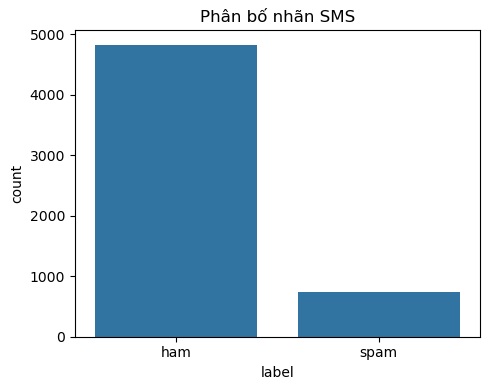

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
FIG_DIR.mkdir(exist_ok=True)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

df = pd.read_csv(DATA_DIR / 'spam.csv', encoding='latin-1')
print('Shape ban đầu:', df.shape)
print('Tên cột ban đểu:', df.columns.tolist())
df = df.iloc[:, :2].copy()
df.columns = ['label', 'text']
df['text'] = df['text'].fillna('').astype(str)
print('Missing values:'); print(df.isna().sum())
print('Target distribution:'); print(df['label'].value_counts())
assert len(df) == 5572
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='label', order=['ham', 'spam'])
plt.title('Phân bố nhãn SMS')
plt.tight_layout(); plt.savefig(FIG_DIR / '08_spam_target_distribution.png', dpi=150); plt.show()


## 2. Tiền xử lý, train và tuning

`CountVectorizer` nằm trong `Pipeline` để trênh data leakage.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])
print('Kích thước train/test:', len(X_train), len(X_test))
assert len(X_test) == 1115
pipe = Pipeline([('vectorizer', CountVectorizer()), ('classifier', MultinomialNB())])
grid = GridSearchCV(pipe, {'vectorizer__ngram_range': [(1, 1), (1, 2)], 'classifier__alpha': [0.1, 0.5, 1.0]}, scoring='f1_macro', cv=5, n_jobs=-1, error_score=np.nan)
grid.fit(X_train, y_train)
model = grid.best_estimator_
print('Best params:', grid.best_params_)
print('Best CV F1:', round(grid.best_score_, 4))


Kích thước train/test: 4457 1115


Best params: {'classifier__alpha': 0.5, 'vectorizer__ngram_range': (1, 1)}
Best CV F1: 0.9731


## 3. Đánh giá

accuracy     0.9857
precision    0.9650
recall       0.9262
f1           0.9452
roc_auc      0.9843
dtype: float64
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.97      0.93      0.95       149

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



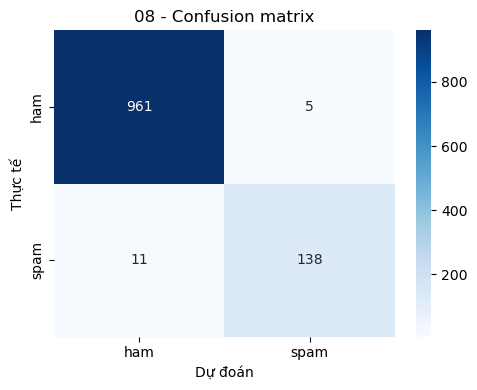

Nhận xét: MultinomialNB phù hợp với vector đếm không âm của văn bản; CV chọn n-gram/alpha trên train, không dùng test để tuning.
Đã cập nhật: D:\ML_Lab_Group_2026\Lab05_ModelTraining\Lab05\figures\results_summary.csv


In [3]:
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]
metrics = {'accuracy': accuracy_score(y_test, y_pred), 'precision': precision_score(y_test, y_pred, pos_label='spam'), 'recall': recall_score(y_test, y_pred, pos_label='spam'), 'f1': f1_score(y_test, y_pred, pos_label='spam'), 'roc_auc': roc_auc_score((y_test == 'spam').astype(int), y_score)}
print(pd.Series(metrics).round(4))
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred, labels=['ham', 'spam'])
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.xlabel('Dự đoán'); plt.ylabel('Thực tế'); plt.title('08 - Confusion matrix'); plt.tight_layout(); plt.savefig(FIG_DIR / '08_spam_confusion_matrix.png', dpi=150); plt.show()
print('Nhận xét: MultinomialNB phù hợp với vector đếm không âm của văn bản; CV chọn n-gram/alpha trên train, không dùng test để tuning.')
summary_path = FIG_DIR / 'results_summary.csv'
columns = ['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']
summary = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame(columns=columns)
summary = summary[summary['notebook'] != '08_spam_nb']
summary.loc[len(summary)] = ['08_spam_nb', 'spam.csv', 'CountVectorizer + MultinomialNB', str(grid.best_params_), *[metrics[c] for c in columns[4:]]]
summary.to_csv(summary_path, index=False); print('Đã cập nhật:', summary_path)
